# IND320 Compulsory Assignment 2

This notebook documents the second compulsory assignment in IND320. It extends the reservoir dashboard from Part 1 by replacing the local CSV source with the NVE Magasinstatistikk API and by adding a pipeline for ENTSO-E cross-border physical flow data using Cassandra, Spark and MongoDB.

## Project Links

- GitHub repository: https://github.com/VasiliiAnderson/ind320-project
- Streamlit application: https://vasilii-ind320.streamlit.app/

## 1. Setup and Imports

Secrets are stored locally in `.env` and are excluded from Git. The notebook expects `MONGODB_URI` and `ENTSOE_TOKEN`. On Windows, Spark also requires a working local Hadoop setup. Adjust the path below if Hadoop is installed elsewhere.

In [1]:
# Import standard-library tools for environment configuration,
# file paths, timing and parsing XML responses.
import os
import time
import xml.etree.ElementTree as ET
from pathlib import Path

# Import libraries used for visualisation, data processing,
# API requests and database connections.
import matplotlib.pyplot as plt
import pandas as pd
import requests
from cassandra.cluster import Cluster
from dotenv import load_dotenv
from pymongo import MongoClient

# Identify the project root so the notebook can be run either
# from the project directory or from the notebooks directory.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / ".env").exists() and (PROJECT_ROOT.parent / ".env").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load local environment variables such as database credentials
# and the ENTSO-E API token without hard-coding them in the notebook.
load_dotenv(PROJECT_ROOT / ".env")

# Configure the local Hadoop installation on Windows if HADOOP_HOME
# has not already been defined in the system environment.
if os.name == "nt" and not os.environ.get("HADOOP_HOME"):
    os.environ["HADOOP_HOME"] = r"C:\Hadoop\hadoop-3.3.5"
    os.environ["PATH"] = os.path.join(os.environ["HADOOP_HOME"], "bin") + os.pathsep + os.environ["PATH"]

# Verify that the required local configuration is available.
# Only the presence of credentials is printed, never their actual values.
print("Project root:", PROJECT_ROOT)
print("HADOOP_HOME:", os.environ.get("HADOOP_HOME"))
print("MongoDB URI available:", bool(os.getenv("MONGODB_URI")))
print("ENTSO-E token available:", bool(os.getenv("ENTSOE_TOKEN")))

Project root: c:\dev\IND320\project
HADOOP_HOME: C:\Hadoop\hadoop-3.3.5
MongoDB URI available: True
ENTSO-E token available: True


## 2. NVE Magasinstatistikk API

The reservoir statistics used in Compulsory Assignment 1 were loaded from a local CSV file. In Part 2, the data are retrieved directly from the NVE Magasinstatistikk API.

### 2.1 Retrieve Area Information

In [2]:
# Base URL for the NVE Magasinstatistikk API.
NVE_BASE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

# Request metadata about the available geographical area types
# and area numbers from the NVE API.
areas_response = requests.get(
    f"{NVE_BASE_URL}/HentOmråder",
    timeout=30,
)

# Stop execution if the API returns an unsuccessful HTTP status code.
areas_response.raise_for_status()

# Convert the JSON response to a Python object for inspection.
areas = areas_response.json()

# Display the available area information.
areas

[{'land': [{'navn': 'Norge',
    'navn_langt': 'Norge',
    'beskrivelse': 'Hele landet',
    'omrType': 'NO',
    'omrnr': 0}],
  'elspot': [{'navn': 'NO 1',
    'navn_langt': 'Elspotområde 1',
    'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).',
    'omrType': 'EL',
    'omrnr': 1},
   {'navn': 'NO 2',
    'navn_langt': 'Elspotområde 2',
    'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.',
    'omrType': 'EL',
    'omrnr': 2},
   {'navn': 'NO 3',
    'navn_langt': 'Elspotområde 3',
    'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.',
    'omrType': 'EL',
    'omrnr': 3},
   {'navn': 'NO 4',
    'navn_langt': 'Elspotområde 4',
    'beskrivelse': 'Nord-Norge. Omfatter resten av

### 2.2 Retrieve Reservoir Data

In [3]:
# Request the publicly available reservoir statistics from the NVE API.
reservoir_response = requests.get(
    f"{NVE_BASE_URL}/HentOffentligData",
    timeout=30,
)

# Stop execution if the API request was unsuccessful.
reservoir_response.raise_for_status()

# Convert the returned JSON data into a Pandas DataFrame
# so it can be cleaned, analysed and visualised.
reservoir_df = pd.DataFrame(
    reservoir_response.json()
)

# Inspect the number of retrieved observations and preview
# the first rows of the dataset.
print("Rows:", len(reservoir_df))
reservoir_df.head()

Rows: 14931


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


### 2.3 Prepare the Data

In [4]:
# Rename the original NVE column names to shorter and more
# descriptive English names used throughout the project.
reservoir_df = reservoir_df.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_twh",
    "fylling_TWh": "stored_energy_twh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "previous_week_fill_level",
    "endring_fyllingsgrad": "change_in_fill_level",
})

# Convert the main date column to pandas datetime format.
reservoir_df["date"] = pd.to_datetime(
    reservoir_df["date"]
)

# Replace the placeholder date used by the API for missing publication dates.
reservoir_df["next_publication_date"] = (
    reservoir_df["next_publication_date"]
    .replace("0001-01-01T00:00:00", pd.NA)
)

# Convert valid publication dates to datetime values and
# coerce invalid or missing values to NaT.
reservoir_df["next_publication_date"] = pd.to_datetime(
    reservoir_df["next_publication_date"],
    errors="coerce",
)

# Sort the dataset chronologically and by geographical area
# to make later filtering and plotting more consistent.
reservoir_df = (
    reservoir_df
    .sort_values(
        ["date", "area_type", "area_number"]
    )
    .reset_index(drop=True)
)

# Inspect which area numbers belong to each area type.
print("Area types and associated area numbers:")
display(
    reservoir_df
    .groupby("area_type")["area_number"]
    .unique()
)

# Review the resulting column types and missing values.
reservoir_df.info()

Area types and associated area numbers:


area_type
EL      [1, 2, 3, 4, 5]
NO                  [0]
VASS          [1, 2, 3]
Name: area_number, dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 14931 entries, 0 to 14930
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      14931 non-null  datetime64[us]
 1   area_type                 14931 non-null  str           
 2   area_number               14931 non-null  int64         
 3   iso_year                  14931 non-null  int64         
 4   iso_week                  14931 non-null  int64         
 5   fill_level                14931 non-null  float64       
 6   capacity_twh              14931 non-null  float64       
 7   stored_energy_twh         14931 non-null  float64       
 8   next_publication_date     3609 non-null   datetime64[us]
 9   previous_week_fill_level  14931 non-null  float64       
 10  change_in_fill_level      14931 non-null  float64       
dtypes: datetime64[us](2), float64(5), int64(3), str(1)
memory usage: 1.3 MB


### 2.4 Reservoir Visualisation

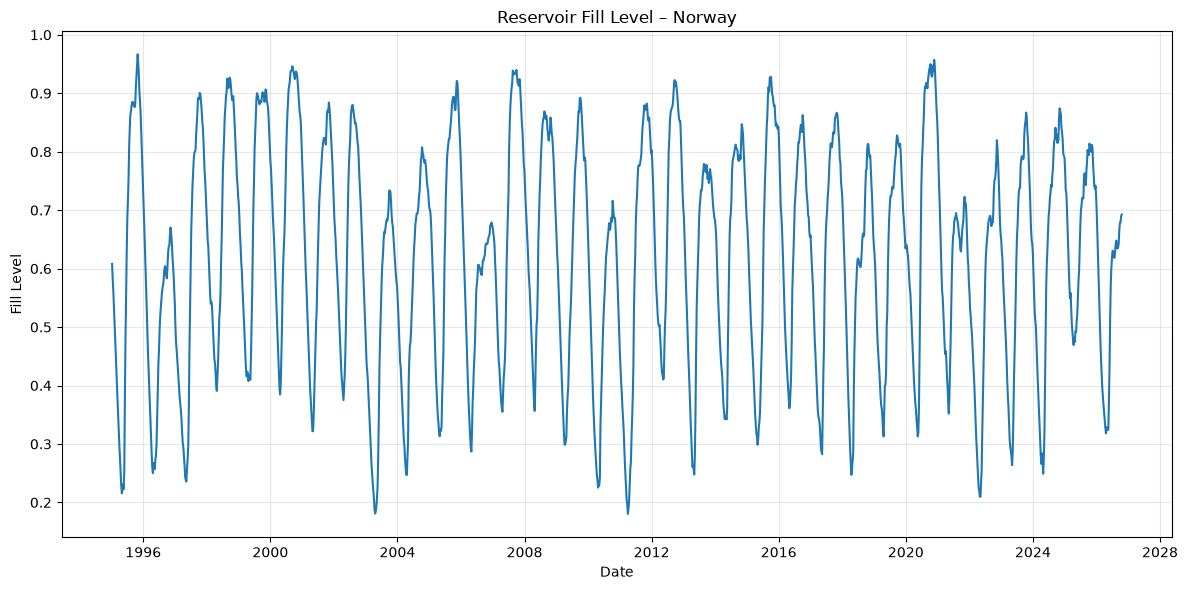

In [5]:
# Select the national reservoir observations for Norway and
# sort them chronologically before plotting.
national_data = reservoir_df[(reservoir_df["area_type"] == "NO") & (reservoir_df["area_number"] == 0)].sort_values("date").copy()

# Create a time-series plot of the national reservoir fill level.
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(national_data["date"], national_data["fill_level"])

# Add descriptive labels and improve readability of the figure.
ax.set_title("Reservoir Fill Level – Norway")
ax.set_xlabel("Date")
ax.set_ylabel("Fill Level")
ax.grid(alpha=0.3)

# Adjust the layout and display the completed plot.
fig.tight_layout()
plt.show()

## 3. Cassandra and Spark

Cassandra is run locally in Docker and exposed on port `9042`. This section creates a small test table and verifies that Spark can read from Cassandra.

### 3.1 Create a Cassandra Connection Test

In [ ]:
# Connect to the locally running Cassandra instance.
cluster = Cluster(["127.0.0.1"], port=9042)
cassandra_session = cluster.connect()

# Create a small test keyspace used to verify the local Cassandra setup.
cassandra_session.execute("""
CREATE KEYSPACE IF NOT EXISTS ind320_test
WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")

# Create a simple table that can be read later through Spark.
cassandra_session.execute("""
CREATE TABLE IF NOT EXISTS ind320_test.spark_test (
    id int PRIMARY KEY,
    value text
)
""")

# Insert one test record so the Spark-Cassandra connection
# can be verified with an actual read operation.
cassandra_session.execute("""
INSERT INTO ind320_test.spark_test (id, value)
VALUES (1, 'Spark-Cassandra connection works')
""")

# Confirm that the Cassandra test table has been prepared successfully.
print("Cassandra test table is ready.")

NoHostAvailable: ('Unable to connect to any servers', {'127.0.0.1:9042': ConnectionShutdown('Connection to 127.0.0.1:9042 was closed'), '::1:9042': ConnectionShutdown('Connection to ::1:9042 was closed')})

### 3.2 Configure Spark

In [ ]:
# Import SparkSession, which is used as the main entry point
# for working with Apache Spark from Python.
from pyspark.sql import SparkSession

# Create a local Spark session configured to communicate
# with the Cassandra instance running on localhost.
spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IND320SparkCassandra")

    # Load the DataStax connector required for communication
    # between Apache Spark and Cassandra.
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1",
    )

    # Define the host and port of the local Cassandra instance.
    .config(
        "spark.cassandra.connection.host",
        "localhost",
    )
    .config(
        "spark.cassandra.connection.port",
        "9042",
    )

    # Enable the Cassandra Spark extensions and catalog.
    .config(
        "spark.sql.extensions",
        "com.datastax.spark.connector.CassandraSparkExtensions",
    )
    .config(
        "spark.sql.catalog.mycatalog",
        "com.datastax.spark.connector.datasource.CassandraCatalog",
    )

    # Use UTC throughout the Spark session to keep timestamps
    # consistent with the ENTSO-E data.
    .config(
        "spark.sql.session.timeZone",
        "UTC",
    )

    # Use conservative Cassandra write settings to reduce the
    # risk of timeouts when writing the complete dataset locally.
    .config(
        "spark.cassandra.output.concurrent.writes",
        "1",
    )
    .config(
        "spark.cassandra.output.batch.size.rows",
        "10",
    )
    .config(
        "spark.cassandra.output.throughputMBPerSec",
        "1",
    )
    .config(
        "spark.cassandra.output.consistency.level",
        "LOCAL_ONE",
    )
    .getOrCreate()
)

# Confirm that the Spark session started successfully.
print("Spark version:", spark.version)

Spark version: 3.5.9


### 3.3 Verify the Spark–Cassandra Connection

In [ ]:
# Read the small test table from Cassandra using the
# Spark Cassandra connector configured in the previous cell.
spark_cassandra_test = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320_test",
        table="spark_test",
    )
    .load()
)

# Display the test record to confirm that Spark can
# successfully read data from Cassandra.
spark_cassandra_test.show(truncate=False)

# Close the direct Cassandra connection because the
# connection test is complete. Spark remains active.
cassandra_session.shutdown()
cluster.shutdown()

+---+--------------------------------+
|id |value                           |
+---+--------------------------------+
|1  |Spark-Cassandra connection works|
+---+--------------------------------+



## 4. ENTSO-E API

Cross-border physical flow data are retrieved from the ENTSO-E Transparency Platform Web API. The security token is read from `.env` and is never printed or stored in the notebook.

### 4.1 Authentication and API Test

In [ ]:
# Read the ENTSO-E API token from the local environment
# and define the Transparency Platform API endpoint.
ENTSOE_TOKEN = os.getenv("ENTSOE_TOKEN")
ENTSOE_API_URL = "https://web-api.tp.entsoe.eu/api"

# Stop execution if the token has not been configured locally.
if not ENTSOE_TOKEN:
    raise RuntimeError(
        "ENTSOE_TOKEN is missing. Add it to the local .env file before continuing."
    )

# Define the ENTSO-E domain codes for the NO2 bidding zone
# and the Germany-Luxembourg bidding zone used in this test request.
NO2 = "10YNO-2--------T"
DE_LU = "10Y1001A1001A82H"

# Build a small one-day request for physical cross-border flow data.
# Document type A11 represents physical flow.
test_params = {
    "securityToken": ENTSOE_TOKEN,
    "documentType": "A11",
    "out_Domain": NO2,
    "in_Domain": DE_LU,
    "periodStart": "202610010000",
    "periodEnd": "202610020000",
}

# Send the request to the ENTSO-E API.
entsoe_test_response = requests.get(
    ENTSOE_API_URL,
    params=test_params,
    timeout=60,
)

# Raise an exception if the HTTP request was unsuccessful.
entsoe_test_response.raise_for_status()

# Inspect basic response information and the beginning of the XML
# document to verify that the API connection works as expected.
print("Status code:", entsoe_test_response.status_code)
print("Content type:", entsoe_test_response.headers.get("Content-Type"))
print(entsoe_test_response.text[:120])

Status code: 200
Content type: text/xml
<?xml version="1.0" encoding="utf-8"?>
<Publication_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-3:publicationdoc


### 4.2 Parse Physical Flow Data

In [ ]:
def parse_entsoe_physical_flow(xml_text, connection, direction):
    """Parse ENTSO-E cross-border physical flow XML into a pandas DataFrame."""

    # Parse the XML response and identify the root element.
    root = ET.fromstring(xml_text)

    # ENTSO-E may return an acknowledgement document instead of data.
    # If this happens, extract the error message and stop execution.
    if root.tag.endswith("Acknowledgement_MarketDocument"):
        reason = root.findtext(".//{*}text") or "Unknown ENTSO-E API error"
        raise RuntimeError(reason)

    # Extract the XML namespace used throughout the ENTSO-E document.
    namespace = {"ns": root.tag.split("}")[0].strip("{")}

    # Store all parsed observations before converting them
    # to a Pandas dataframe.
    rows = []

    # Each TimeSeries represents a physical-flow time series
    # between an outgoing and incoming ENTSO-E domain.
    for time_series in root.findall("ns:TimeSeries", namespace):
        out_domain = time_series.findtext("ns:out_Domain.mRID", namespaces=namespace)
        in_domain = time_series.findtext("ns:in_Domain.mRID", namespaces=namespace)

        # A time series may contain one or more periods with their
        # own start time and temporal resolution.
        for period in time_series.findall("ns:Period", namespace):
            start = pd.Timestamp(period.findtext("ns:timeInterval/ns:start", namespaces=namespace))
            resolution = period.findtext("ns:resolution", namespaces=namespace)

            # Convert ISO 8601 resolutions such as PT15M or PT1H
            # into a common interval length measured in minutes.
            if resolution.startswith("PT") and resolution.endswith("M"):
                minutes = int(resolution.removeprefix("PT").removesuffix("M"))
            elif resolution.startswith("PT") and resolution.endswith("H"):
                minutes = int(resolution.removeprefix("PT").removesuffix("H")) * 60
            else:
                raise ValueError(f"Unsupported ENTSO-E resolution: {resolution}")

            # Convert each ENTSO-E point into a timestamped observation.
            for point in period.findall("ns:Point", namespace):
                position = int(point.findtext("ns:position", namespaces=namespace))
                quantity_mw = float(point.findtext("ns:quantity", namespaces=namespace))

                # ENTSO-E points are position-based, so calculate the
                # actual timestamp from the period start and interval length.
                timestamp = start + pd.Timedelta(minutes=(position - 1) * minutes)

                # Store both power in MW and the corresponding energy
                # for the interval in MWh.
                rows.append({
                    "timestamp": timestamp,
                    "connection": connection,
                    "direction": direction,
                    "out_domain": out_domain,
                    "in_domain": in_domain,
                    "quantity_mw": quantity_mw,
                    "interval_minutes": minutes,
                    "energy_mwh": quantity_mw * minutes / 60,
                })

    # Return the parsed observations as a structured DataFrame.
    return pd.DataFrame(rows)

In [ ]:
# Parse the XML response from the test request into a structured
# DataFrame using the parser defined in the previous cell.
test_flow_df = parse_entsoe_physical_flow(
    entsoe_test_response.text,
    connection="NO2-DE_LU",
    direction="Export",
)

# Inspect the first observations to verify that timestamps,
# direction, physical flow and calculated energy were parsed correctly.
test_flow_df[
    [
        "timestamp",
        "connection",
        "direction",
        "quantity_mw",
        "energy_mwh",
    ]
].head(10)

,timestamp,connection,direction,quantity_mw,energy_mwh
0,2026-10-01 00:00:00+00:00,NO2-DE_LU,Export,1047.52,261.88
1,2026-10-01 00:15:00+00:00,NO2-DE_LU,Export,1043.84,260.96
2,2026-10-01 00:30:00+00:00,NO2-DE_LU,Export,1080.80,270.20
3,2026-10-01 00:45:00+00:00,NO2-DE_LU,Export,1114.56,278.64
4,2026-10-01 01:00:00+00:00,NO2-DE_LU,Export,1226.08,306.52
5,2026-10-01 01:15:00+00:00,NO2-DE_LU,Export,1245.76,311.44
6,2026-10-01 01:30:00+00:00,NO2-DE_LU,Export,1238.40,309.60
7,2026-10-01 01:45:00+00:00,NO2-DE_LU,Export,1289.92,322.48
8,2026-10-01 02:00:00+00:00,NO2-DE_LU,Export,1301.92,325.48
9,2026-10-01 02:15:00+00:00,NO2-DE_LU,Export,1296.64,324.16


### 4.3 Reusable API Function

In [ ]:
def fetch_entsoe_flow(
    out_domain,
    in_domain,
    period_start,
    period_end,
    connection,
    direction,
):
    """Download and parse one ENTSO-E physical-flow request."""

    # Build the query parameters required by the ENTSO-E API.
    # The requested time interval is formatted using the API's
    # expected YYYYMMDDHHMM representation.
    params = {
        "securityToken": ENTSOE_TOKEN,
        "documentType": "A11",
        "out_Domain": out_domain,
        "in_Domain": in_domain,
        "periodStart": period_start.strftime("%Y%m%d%H%M"),
        "periodEnd": period_end.strftime("%Y%m%d%H%M"),
    }

    # Send the API request for one connection, direction
    # and time period.
    response = requests.get(
        ENTSOE_API_URL,
        params=params,
        timeout=60,
    )

    # Stop execution if the HTTP request was unsuccessful.
    response.raise_for_status()

    # Parse the returned ENTSO-E XML and return the result
    # directly as a structured Pandas DataFrame.
    return parse_entsoe_physical_flow(
        response.text,
        connection=connection,
        direction=direction,
    )

### 4.4 Cross-Border Connections

In [ ]:
# Map each Norwegian cross-border connection to the corresponding
# ENTSO-E domain codes for the Norwegian and neighbouring bidding zones.
CONNECTIONS = {
    "NO1-SE3": {
        "norway": "10YNO-1--------2",
        "foreign": "10Y1001A1001A46L",
    },
    "NO2-DK1": {
        "norway": "10YNO-2--------T",
        "foreign": "10YDK-1--------W",
    },
    "NO2-DE_LU": {
        "norway": "10YNO-2--------T",
        "foreign": "10Y1001A1001A82H",
    },
    "NO2-NL": {
        "norway": "10YNO-2--------T",
        "foreign": "10YNL----------L",
    },
    "NO2-GB": {
        "norway": "10YNO-2--------T",
        "foreign": "10YGB----------A",
    },
    "NO3-SE2": {
        "norway": "10YNO-3--------J",
        "foreign": "10Y1001A1001A45N",
    },
    "NO4-SE1": {
        "norway": "10YNO-4--------9",
        "foreign": "10Y1001A1001A44P",
    },
    "NO4-SE2": {
        "norway": "10YNO-4--------9",
        "foreign": "10Y1001A1001A45N",
    },
    "NO4-FI": {
        "norway": "10YNO-4--------9",
        "foreign": "10YFI-1--------U",
    },
}

# Display the configured connections for verification.
CONNECTIONS

{'NO1-SE3': {'norway': '10YNO-1--------2', 'foreign': '10Y1001A1001A46L'},
 'NO2-DK1': {'norway': '10YNO-2--------T', 'foreign': '10YDK-1--------W'},
 'NO2-DE_LU': {'norway': '10YNO-2--------T', 'foreign': '10Y1001A1001A82H'},
 'NO2-NL': {'norway': '10YNO-2--------T', 'foreign': '10YNL----------L'},
 'NO2-GB': {'norway': '10YNO-2--------T', 'foreign': '10YGB----------A'},
 'NO3-SE2': {'norway': '10YNO-3--------J', 'foreign': '10Y1001A1001A45N'},
 'NO4-SE1': {'norway': '10YNO-4--------9', 'foreign': '10Y1001A1001A44P'},
 'NO4-SE2': {'norway': '10YNO-4--------9', 'foreign': '10Y1001A1001A45N'},
 'NO4-FI': {'norway': '10YNO-4--------9', 'foreign': '10YFI-1--------U'}}

### 4.5 Retrieve the Last Two Years

In [ ]:
def fetch_connection_two_years(
    connection_name,
    connection_info,
    start_date,
    end_date,
):
    """Download both import and export data for one connection in chunks of at most one year."""

    # Store each downloaded DataFrame before combining them
    # into one complete dataset for the selected connection.
    all_frames = []

    # Start with the beginning of the requested two-year period.
    period_start = start_date

    # Split the request into chunks of at most one year to stay
    # within the time-range limitations of the ENTSO-E API.
    while period_start < end_date:
        period_end = min(
            period_start + pd.DateOffset(years=1),
            end_date,
        )

        # Retrieve the ENTSO-E domain codes for the Norwegian
        # and neighbouring bidding zones.
        norway = connection_info["norway"]
        foreign = connection_info["foreign"]

        # Print progress information while the API data are downloaded.
        print(
            f"Downloading {connection_name}: "
            f"{period_start.date()} to {period_end.date()}"
        )

        # Download electricity flowing out of Norway.
        export_df = fetch_entsoe_flow(
            out_domain=norway,
            in_domain=foreign,
            period_start=period_start,
            period_end=period_end,
            connection=connection_name,
            direction="Export",
        )

        # Download electricity flowing into Norway.
        import_df = fetch_entsoe_flow(
            out_domain=foreign,
            in_domain=norway,
            period_start=period_start,
            period_end=period_end,
            connection=connection_name,
            direction="Import",
        )

        # Add both directions to the list of downloaded data.
        all_frames.extend([
            export_df,
            import_df,
        ])

        # Move to the next time interval.
        period_start = period_end

    # Combine all downloaded periods and directions into one DataFrame.
    return pd.concat(
        all_frames,
        ignore_index=True,
    )

In [ ]:
# Use the current UTC date as the end of the requested ENTSO-E period.
# Normalising the timestamp removes the time-of-day component.
two_year_end = pd.Timestamp.now(tz="UTC").normalize()

# Define the start date exactly two years before the end date.
two_year_start = two_year_end - pd.DateOffset(years=2)

# Display the resulting interval for verification before downloading.
print(
    "Download period:",
    two_year_start,
    "to",
    two_year_end,
)

Download period: 2024-10-20 00:00:00+00:00 to 2026-10-20 00:00:00+00:00


In [ ]:
# Store the completed DataFrame for each cross-border connection
# before combining them into one dataset.
all_connections = []

# Loop through every Norwegian cross-border connection
# defined in the CONNECTIONS dictionary.
for connection_name, connection_info in CONNECTIONS.items():
    print(f"\nProcessing {connection_name}...")

    try:
        # Download approximately two years of import and export
        # observations for the current connection.
        connection_df = fetch_connection_two_years(
            connection_name=connection_name,
            connection_info=connection_info,
            start_date=two_year_start,
            end_date=two_year_end,
        )

        # Report the number of observations retrieved successfully.
        print(
            f"{connection_name}: "
            f"{len(connection_df):,} observations"
        )

        # Save the completed connection dataset for later concatenation.
        all_connections.append(connection_df)

        # Pause briefly between connections to avoid sending
        # requests to the ENTSO-E API too aggressively.
        time.sleep(1)

    except Exception as error:
        # Continue with the remaining connections if one download fails,
        # while printing the error for later inspection.
        print(
            f"Could not download {connection_name}: "
            f"{error}"
        )


Processing NO1-SE3...
NO1-SE3: 47,323 observations

Processing NO2-DK1...
NO2-DK1: 60,096 observations

Processing NO2-DE_LU...
NO2-DE_LU: 63,913 observations

Processing NO2-NL...
NO2-NL: 37,831 observations

Processing NO2-GB...
NO2-GB: 67,495 observations

Processing NO3-SE2...
NO3-SE2: 47,053 observations

Processing NO4-SE1...
NO4-SE1: 47,533 observations

Processing NO4-SE2...
NO4-SE2: 46,512 observations

Processing NO4-FI...
NO4-FI: 65,552 observations


In [ ]:
# Stop execution if none of the configured connections
# returned data successfully.
if not all_connections:
    raise RuntimeError(
        "No ENTSO-E data were downloaded."
    )

# Combine the downloaded DataFrames for all connections
# into one complete ENTSO-E dataset.
entsoe_df = pd.concat(
    all_connections,
    ignore_index=True,
)

# Sort the observations by connection, timestamp and direction
# to create a consistent chronological dataset.
entsoe_df = (
    entsoe_df
    .sort_values(
        ["connection", "timestamp", "direction"]
    )
    .reset_index(drop=True)
)

# Preview the combined dataset.
entsoe_df.head()

,timestamp,connection,direction,out_domain,in_domain,quantity_mw,interval_minutes,energy_mwh
0,2024-10-20 00:00:00+00:00,NO1-SE3,Export,10YNO-1--------2,10Y1001A1001A46L,0.0000,60,0.0000
1,2024-10-20 00:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1002.2950,60,1002.2950
2,2024-10-20 01:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1064.2175,60,1064.2175
3,2024-10-20 02:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1084.2900,60,1084.2900
4,2024-10-20 03:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1084.1575,60,1084.1575


### 4.6 Validate the Downloaded Data

In [ ]:
# Summarise the number of observations and total transferred energy
# for each cross-border connection and flow direction.
summary_df = entsoe_df.groupby(
    ["connection", "direction"]
).agg(
    observations=("quantity_mw", "size"),
    total_mwh=("energy_mwh", "sum"),
)

# Display the connection-level summary.
display(summary_df)

# Inspect the available connections and the overall dataset size.
print(
    "Connections:",
    sorted(entsoe_df["connection"].unique()),
)
print(
    "Total observations:",
    f"{len(entsoe_df):,}",
)

# Verify the actual time span covered by the downloaded data.
print(
    "Period:",
    entsoe_df["timestamp"].min(),
    "to",
    entsoe_df["timestamp"].max(),
)

# Check for duplicate primary-key combinations before the data
# are prepared for storage in Cassandra.
print(
    "Duplicate rows:",
    entsoe_df.duplicated(
        subset=[
            "connection",
            "direction",
            "timestamp",
        ]
    ).sum(),
)

# Check whether any variables contain missing values.
print("\nMissing values:")
print(entsoe_df.isna().sum())

observations     total_mwh
connection direction                            
NO1-SE3    Export            12627  3.075436e+06
           Import            34696  1.202813e+07
NO2-DE_LU  Export            47181  1.136082e+07
           Import            16732  3.077390e+06
NO2-DK1    Export            41271  1.388483e+07
           Import            18825  3.981912e+06
NO2-GB     Export            58142  1.748635e+07
           Import             9353  1.826499e+06
NO2-NL     Export            28387  3.465896e+06
           Import             9444  8.132092e+05
NO3-SE2    Export            15039  1.522974e+06
           Import            32014  3.532964e+06
NO4-FI     Export            48681  5.607321e+05
           Import            16871  8.736542e+04
NO4-SE1    Export            31616  3.003654e+06
           Import            15917  1.330112e+06
NO4-SE2    Export            29610  9.583882e+05
           Import            16902  4.289905e+05

Connections: ['NO1-SE3', 'NO2-DE_LU', 'NO2-DK1', 'NO2-GB', 'NO2-NL', 'NO3-SE2', 'NO4-FI', 'NO4-SE1', 'NO4-SE2']
Total observations: 483,308
Period: 2024-10-20 00:00:00+00:00 to 2026-10-19 23:45:00+00:00
Duplicate rows: 0

Missing values:
timestamp           0
connection          0
direction           0
out_domain          0
in_domain           0
quantity_mw         0
interval_minutes    0
energy_mwh          0
dtype: int64


## 5. Store ENTSO-E Data in Cassandra

The complete ENTSO-E dataset is stored in Cassandra. Spark is used to create the distributed DataFrame and write it through the Spark–Cassandra connector.

### 5.1 Create the Cassandra Table

In [ ]:
# Connect to the locally running Cassandra instance.
cluster = Cluster(["localhost"], port=9042)
cassandra_session = cluster.connect()

# Create the keyspace used for the assignment data.
# A replication factor of 1 is sufficient for this local single-node setup.
cassandra_session.execute("""
CREATE KEYSPACE IF NOT EXISTS ind320
WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")

# Create the table used to store the ENTSO-E physical-flow observations.
# Connection and direction form the partition key, while timestamp_utc
# identifies individual observations within each partition.
cassandra_session.execute("""
CREATE TABLE IF NOT EXISTS ind320.entsoe_physical_flow (
    connection text,
    direction text,
    timestamp_utc timestamp,
    out_domain text,
    in_domain text,
    quantity_mw double,
    interval_minutes int,
    energy_mwh double,
    PRIMARY KEY ((connection, direction), timestamp_utc)
)
""")

# Confirm that the Cassandra table is available before writing data.
print("Cassandra table ind320.entsoe_physical_flow is ready.")

Cassandra table ind320.entsoe_physical_flow is ready.


### 5.2 Convert the ENTSO-E Data to Spark

In [ ]:
# Import explicit Spark data types so the DataFrame schema
# matches the structure expected by the Cassandra table.
from pyspark.sql.types import (
    DoubleType,
    IntegerType,
    StringType,
    StructField,
    StructType,
    TimestampType,
)

# Work on a copy of the Pandas DataFrame before converting it to Spark.
spark_input = entsoe_df.copy()

# Convert the timezone-aware ENTSO-E timestamps to UTC and remove
# timezone information because Spark TimestampType stores naive timestamps.
spark_input["timestamp_utc"] = (
    spark_input["timestamp"]
    .dt.tz_convert("UTC")
    .dt.tz_localize(None)
)

# Remove the original timestamp column after creating timestamp_utc.
spark_input = spark_input.drop(columns=["timestamp"])

# Define the Spark schema explicitly to ensure consistent data types
# when the DataFrame is written to Cassandra.
spark_schema = StructType([
    StructField("connection", StringType(), False),
    StructField("direction", StringType(), False),
    StructField("out_domain", StringType(), True),
    StructField("in_domain", StringType(), True),
    StructField("quantity_mw", DoubleType(), False),
    StructField("interval_minutes", IntegerType(), False),
    StructField("energy_mwh", DoubleType(), False),
    StructField("timestamp_utc", TimestampType(), False),
])

# Convert each Pandas row to standard Python values that can
# be used safely when constructing the Spark DataFrame.
records = (
    (
        str(row.connection),
        str(row.direction),
        None if pd.isna(row.out_domain) else str(row.out_domain),
        None if pd.isna(row.in_domain) else str(row.in_domain),
        float(row.quantity_mw),
        int(row.interval_minutes),
        float(row.energy_mwh),
        row.timestamp_utc.to_pydatetime(),
    )
    for row in spark_input[[
        "connection",
        "direction",
        "out_domain",
        "in_domain",
        "quantity_mw",
        "interval_minutes",
        "energy_mwh",
        "timestamp_utc",
    ]].itertuples(index=False)
)

# Create the Spark DataFrame using the explicitly defined schema.
spark_df = spark.createDataFrame(
    records,
    schema=spark_schema,
)

# Inspect the schema and a small sample before writing to Cassandra.
spark_df.printSchema()
spark_df.show(5, truncate=False)

root
 |-- connection: string (nullable = false)
 |-- direction: string (nullable = false)
 |-- out_domain: string (nullable = true)
 |-- in_domain: string (nullable = true)
 |-- quantity_mw: double (nullable = false)
 |-- interval_minutes: integer (nullable = false)
 |-- energy_mwh: double (nullable = false)
 |-- timestamp_utc: timestamp (nullable = false)

+----------+---------+----------------+----------------+-----------+----------------+----------+-------------------+
|connection|direction|out_domain      |in_domain       |quantity_mw|interval_minutes|energy_mwh|timestamp_utc      |
+----------+---------+----------------+----------------+-----------+----------------+----------+-------------------+
|NO1-SE3   |Export   |10YNO-1--------2|10Y1001A1001A46L|0.0        |60              |0.0       |2024-10-19 22:00:00|
|NO1-SE3   |Import   |10Y1001A1001A46L|10YNO-1--------2|1002.295   |60              |1002.295  |2024-10-19 22:00:00|
|NO1-SE3   |Import   |10Y1001A1001A46L|10YNO-1--------2

### 5.3 Write to Cassandra

In [ ]:
# Import Spark SQL helper functions used for filtering
# and inspecting duplicate key combinations.
from pyspark.sql import functions as F

# Identify duplicate combinations of connection, direction
# and timestamp, which together must be unique for the
# Cassandra primary-key structure used in this project.
duplicate_keys = (
    spark_df
    .groupBy(
        "connection",
        "direction",
        "timestamp_utc",
    )
    .count()
    .filter(F.col("count") > 1)
)

# Report how many duplicate Cassandra key combinations were found.
print(
    "Duplicate Cassandra keys:",
    duplicate_keys.count(),
)

# Remove duplicate primary-key combinations before writing
# the data to Cassandra. Coalescing to two partitions keeps
# the local write operation relatively conservative.
spark_df_clean = (
    spark_df
    .dropDuplicates(
        [
            "connection",
            "direction",
            "timestamp_utc",
        ]
    )
    .coalesce(2)
)

# Count the rows that are expected to be written after cleaning.
expected_rows = spark_df_clean.count()

# Compare the original and cleaned dataset sizes.
print("Rows before cleaning:", spark_df.count())
print("Rows to write:", expected_rows)

Duplicate Cassandra keys: 44
Rows before cleaning: 483308
Rows to write: 483264


In [ ]:
# Remove any previously stored observations so the notebook
# can be rerun from scratch without creating stale or duplicate data.
cassandra_session.execute(
    "TRUNCATE ind320.entsoe_physical_flow"
)

# Write the cleaned Spark DataFrame to the Cassandra table
# using the Spark Cassandra Connector.
(
    spark_df_clean.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(
        keyspace="ind320",
        table="entsoe_physical_flow",
    )
    .save()
)

# Confirm that the write operation completed successfully.
print("ENTSO-E data written to Cassandra.")

ENTSO-E data written to Cassandra.


### 5.4 Read the Data Back with Spark

In [ ]:
# Read the complete ENTSO-E table back from Cassandra using Spark.
# This verifies that the data written in the previous step can
# be retrieved successfully through the Spark Cassandra Connector.
cassandra_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320",
        table="entsoe_physical_flow",
    )
    .load()
)

# Count the rows stored in Cassandra after the write operation.
actual_rows = cassandra_df.count()

# Compare the number of stored rows with the number expected
# after duplicate removal.
print("Expected rows:", expected_rows)
print("Rows in Cassandra:", actual_rows)
print("Match:", expected_rows == actual_rows)

# Display a small sample to inspect the stored values and schema content.
cassandra_df.show(10, truncate=False)

Expected rows: 483264
Rows in Cassandra: 483264
Match: True
+----------+---------+-------------------+----------+----------------+----------------+----------------+-----------+
|connection|direction|timestamp_utc      |energy_mwh|in_domain       |interval_minutes|out_domain      |quantity_mw|
+----------+---------+-------------------+----------+----------------+----------------+----------------+-----------+
|NO2-GB    |Export   |2024-10-19 22:00:00|0.0       |10YGB----------A|15              |10YNO-2--------T|0.0        |
|NO2-GB    |Export   |2024-10-22 06:30:00|0.0025    |10YGB----------A|15              |10YNO-2--------T|0.01       |
|NO2-GB    |Export   |2024-10-22 06:45:00|0.0       |10YGB----------A|15              |10YNO-2--------T|0.0        |
|NO2-GB    |Export   |2024-10-25 10:45:00|8.045     |10YGB----------A|15              |10YNO-2--------T|32.18      |
|NO2-GB    |Export   |2024-10-25 11:00:00|102.1875  |10YGB----------A|15              |10YNO-2--------T|408.75     |
|NO2

In [ ]:
# Close the direct Cassandra session and cluster connection
# after the Cassandra write and verification steps are complete.
cassandra_session.shutdown()
cluster.shutdown()

## 6. Spark Filtering and Visualisation

Only the columns needed for the analysis are selected from Cassandra using Spark. The plots are created from small aggregated or filtered results.

### 6.1 Select Relevant Columns

In [ ]:
# Import Spark SQL functions used to derive additional
# time-related variables from the timestamp column.
from pyspark.sql import functions as F

# Select only the variables needed for analysis and later
# transfer to MongoDB, then derive year and month from the UTC timestamp.
analysis_spark_df = (
    cassandra_df
    .select(
        "timestamp_utc",
        "connection",
        "direction",
        "quantity_mw",
        "energy_mwh",
        "interval_minutes",
        "out_domain",
        "in_domain",
    )
    .withColumn(
        "year",
        F.year("timestamp_utc"),
    )
    .withColumn(
        "month",
        F.month("timestamp_utc"),
    )
)

# Display a small sample of the prepared Spark dataset.
analysis_spark_df.show(5, truncate=False)

+-------------------+----------+---------+-----------+-----------------+----------------+----------------+----------------+----+-----+
|timestamp_utc      |connection|direction|quantity_mw|energy_mwh       |interval_minutes|out_domain      |in_domain       |year|month|
+-------------------+----------+---------+-----------+-----------------+----------------+----------------+----------------+----+-----+
|2024-10-19 22:00:00|NO2-NL    |Import   |0.0        |0.0              |15              |10YNL----------L|10YNO-2--------T|2024|10   |
|2024-10-20 07:45:00|NO2-NL    |Import   |52.52      |13.13            |15              |10YNL----------L|10YNO-2--------T|2024|10   |
|2024-10-20 08:00:00|NO2-NL    |Import   |317.8      |79.45            |15              |10YNL----------L|10YNO-2--------T|2024|10   |
|2024-10-20 08:15:00|NO2-NL    |Import   |320.22     |80.055           |15              |10YNL----------L|10YNO-2--------T|2024|10   |
|2024-10-20 08:30:00|NO2-NL    |Import   |319.73     |7

### 6.2 Annual Import/Export Pie Chart

,direction,total_mwh
0,Export,6.423945e+06
1,Import,7.639865e+05


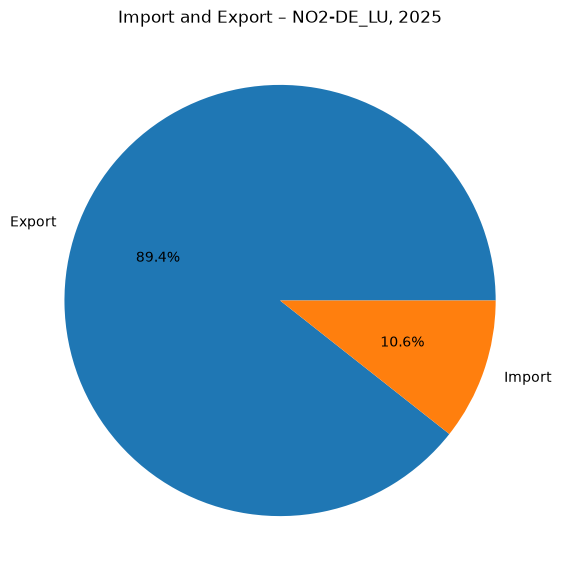

In [ ]:
# Select one connection and one complete calendar year
# for the annual import/export comparison.
analysis_connection = "NO2-DE_LU"
analysis_year = int(two_year_end.year - 1)

# Filter the Spark dataset to the selected connection and year,
# then aggregate transferred energy by import/export direction.
annual_totals = (
    analysis_spark_df
    .filter(
        (F.col("connection") == analysis_connection)
        & (F.col("year") == analysis_year)
    )
    .groupBy("direction")
    .agg(
        F.sum("energy_mwh").alias("total_mwh")
    )
    .orderBy("direction")
)

# Convert the small aggregated Spark result to Pandas
# for plotting with Matplotlib.
annual_totals_pd = annual_totals.toPandas()

# Display the aggregated annual totals before plotting.
display(annual_totals_pd)

# Create a pie chart showing the relative share of
# annual import and export energy for the selected connection.
fig, ax = plt.subplots(figsize=(7, 7))

ax.pie(
    annual_totals_pd["total_mwh"],
    labels=annual_totals_pd["direction"],
    autopct="%1.1f%%",
)

ax.set_title(
    f"Import and Export – {analysis_connection}, {analysis_year}"
)

# Display the completed figure.
plt.show()

### 6.3 Monthly Cross-Border Flow Plot

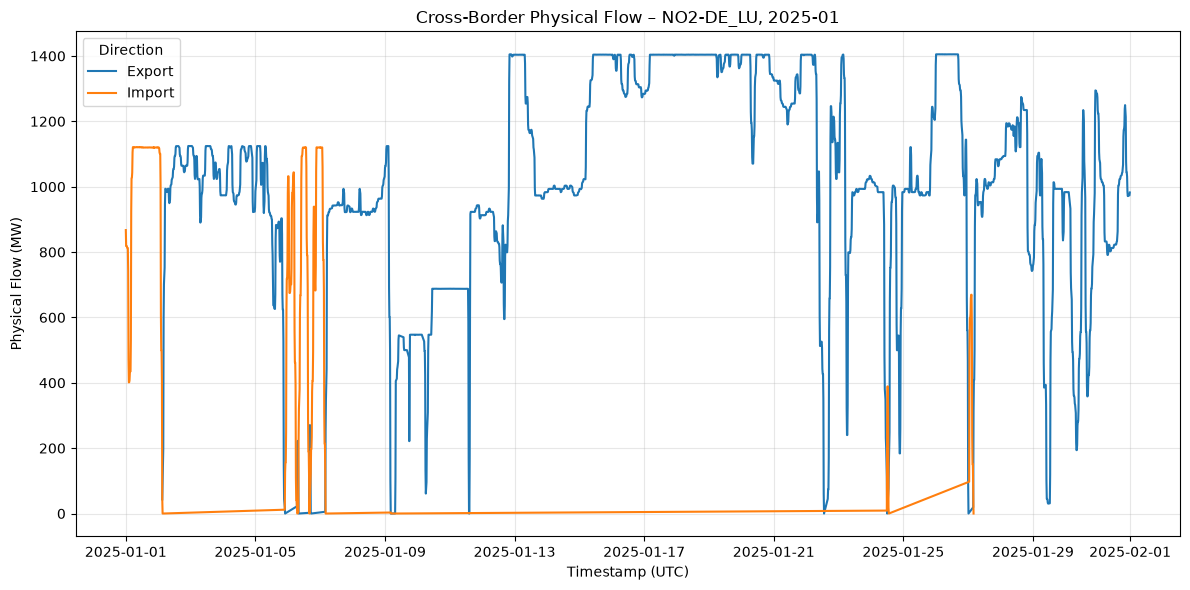

In [ ]:
# Select the month to visualise for the previously chosen
# cross-border connection and analysis year.
analysis_month = 1

# Filter the Spark dataset to the selected connection, year
# and month, then keep only the variables needed for plotting.
monthly_flow_pd = (
    analysis_spark_df
    .filter(
        (F.col("connection") == analysis_connection)
        & (F.col("year") == analysis_year)
        & (F.col("month") == analysis_month)
    )
    .select(
        "timestamp_utc",
        "direction",
        "quantity_mw",
    )
    .orderBy(
        "timestamp_utc",
        "direction",
    )
    .toPandas()
)

# Create the monthly time-series figure.
fig, ax = plt.subplots(figsize=(12, 6))

# Plot separate lines for import and export directions.
for direction, direction_data in monthly_flow_pd.groupby("direction"):
    ax.plot(
        direction_data["timestamp_utc"],
        direction_data["quantity_mw"],
        label=direction,
    )

# Add descriptive labels and formatting.
ax.set_title(
    f"Cross-Border Physical Flow – {analysis_connection}, "
    f"{analysis_year}-{analysis_month:02d}"
)
ax.set_xlabel("Timestamp (UTC)")
ax.set_ylabel("Physical Flow (MW)")
ax.legend(title="Direction")
ax.grid(alpha=0.3)

# Improve spacing and display the completed figure.
fig.tight_layout()
plt.show()

## 7. MongoDB

MongoDB Atlas is used as the remote database that will be accessed by the Streamlit application. The connection string is stored in `.env` and is excluded from Git.

### 7.1 Connection Test

In [ ]:
# Read the MongoDB connection string from the local environment.
mongodb_uri = os.getenv("MONGODB_URI")

# Stop execution if the connection string has not been configured.
if not mongodb_uri:
    raise RuntimeError(
        "MONGODB_URI is missing. Add it to the local .env file before continuing."
    )

# Create a MongoDB client using the configured Atlas connection string.
mongo_client = MongoClient(mongodb_uri)

# Send a lightweight ping command to verify that the remote
# MongoDB Atlas connection is working before inserting data.
mongo_client.admin.command("ping")

# Confirm that the connection test completed successfully.
print("MongoDB connection successful.")

MongoDB connection successful.


### 7.2 Insert Spark-Prepared Data

In [ ]:
# Select the MongoDB database and collection used by the Streamlit app.
mongo_db = mongo_client["ind320"]
mongo_collection = mongo_db["entsoe_physical_flow"]

# Remove existing documents so the notebook can be rerun
# without creating duplicate records in MongoDB.
mongo_collection.delete_many({})

# Create a unique index matching the logical key used for
# each cross-border flow observation.
mongo_collection.create_index(
    [
        ("connection", 1),
        ("direction", 1),
        ("timestamp_utc", 1),
    ],
    unique=True,
)

# Select the Spark columns that should be stored in MongoDB
# and later accessed by the Streamlit application.
mongo_export_df = analysis_spark_df.select(
    "timestamp_utc",
    "connection",
    "direction",
    "quantity_mw",
    "energy_mwh",
    "interval_minutes",
    "out_domain",
    "in_domain",
    "year",
    "month",
)

# Insert the data in batches to avoid sending the complete
# dataset to MongoDB in one very large operation.
batch = []
batch_size = 5000
inserted = 0

# Stream rows from Spark to the local Python process
# instead of collecting the full dataset into memory at once.
for row in mongo_export_df.toLocalIterator():
    batch.append(row.asDict(recursive=True))

    # Insert a batch whenever the configured batch size is reached.
    if len(batch) >= batch_size:
        mongo_collection.insert_many(
            batch,
            ordered=False,
        )
        inserted += len(batch)
        batch = []

# Insert any remaining rows that did not fill a complete batch.
if batch:
    mongo_collection.insert_many(
        batch,
        ordered=False,
    )
    inserted += len(batch)

# Report the total number of documents inserted into MongoDB.
print("Inserted MongoDB documents:", inserted)

Inserted MongoDB documents: 483264


### 7.3 Verify Stored Data

In [ ]:
# Count all documents in the collection to verify that the
# expected dataset was successfully stored in MongoDB.
print(
    "Documents in MongoDB:",
    mongo_collection.count_documents({}),
)

# Retrieve one example document while excluding MongoDB's
# automatically generated _id field.
sample_document = mongo_collection.find_one(
    {},
    {"_id": 0},
)

# Display the example document to inspect the stored structure.
sample_document

Documents in MongoDB: 483264


{'timestamp_utc': datetime.datetime(2024, 10, 20, 0, 0),
 'connection': 'NO2-NL',
 'direction': 'Import',
 'quantity_mw': 0.0,
 'energy_mwh': 0.0,
 'interval_minutes': 15,
 'out_domain': '10YNL----------L',
 'in_domain': '10YNO-2--------T',
 'year': 2024,
 'month': 10}

In [ ]:
# Close the MongoDB client after the insert and verification
# steps are complete to release the database connection cleanly.
mongo_client.close()

## 8. Streamlit Application

The Streamlit application was extended from Compulsory Assignment 1 to include both reservoir statistics and cross-border electricity flow data.

The reservoir pages retrieve data directly from the NVE Magasinstatistikk API rather than from the local CSV file used in Part 1. Users can select between the EL, NO and VASS area types, choose a time interval and explore the data using tables, sparklines and interactive plots.

A separate **Cross-Border Flows** page was added for the ENTSO-E dataset. The processed ENTSO-E data are retrieved from MongoDB Atlas. The page is divided into two columns:

- The left column allows the user to select a cross-border connection and year and displays the annual distribution between import and export as a pie chart.
- The right column allows the user to select one or more months and displays physical electricity flow in MW with separate lines for import and export.

The final application therefore uses two different data pipelines:

**NVE API → Pandas → Streamlit**

**ENTSO-E API → Cassandra → Spark → MongoDB Atlas → Streamlit**

The application is deployed using Streamlit Community Cloud.

**Streamlit application:** https://vasilii-ind320.streamlit.app/

**GitHub repository:** https://github.com/VasiliiAnderson/ind320-project

## 9. AI Usage

Generative AI, primarily ChatGPT, was used as a support tool during the development of this assignment.

AI was used to discuss possible implementation approaches, explain unfamiliar concepts, review code, interpret error messages and suggest debugging steps. It was particularly useful when working with the ENTSO-E XML format, configuring the Spark–Cassandra connection, diagnosing Cassandra write timeouts, setting up MongoDB Atlas and developing the Streamlit interface.

AI was also used to review the organisation of the notebook, improve code comments and help structure the project documentation.

The generated suggestions were not used without verification. Code was executed and tested locally, outputs and error messages were inspected, and proposed solutions were adapted when they did not work in the local environment. For example, the initial Spark configuration resulted in Cassandra write timeouts. Several configurations were tested before using fewer Spark workers, smaller Cassandra write batches and `LOCAL_ONE` consistency, which allowed the complete dataset to be stored successfully.

AI was therefore mainly used as a tool for explanation, debugging and code review. The final implementation was tested and adapted to the requirements and technical environment of the project.

## 10. Work Log

The work on compulsory assignment 2 started by extending the project developed for compulsory assignment 1. A separate Git branch was used so that the existing part 1 implementation could remain unchanged while the new functionality was developed and tested.

The first task was to replace the local reservoir CSV file with data retrieved directly from the NVE Magasinstatistikk API. I explored the API response, converted the returned data into a Pandas DataFrame and renamed the relevant variables. The existing Streamlit pages were then modified so that users could select between EL, NO and VASS area types and choose a time interval for the displayed reservoir data.

The next part of the assignment involved setting up Cassandra and Apache Spark. Cassandra was run locally using Docker. Spark required additional configuration with Java, Hadoop and the Spark Cassandra Connector. I first created a small Cassandra test table and verified that Spark could successfully read data from it before moving on to the complete ENTSO-E dataset.The ENTSO-E Transparency Platform API was then used to retrieve physical cross-border electricity flow data for Norwegian connections covering approximately two years. The API responses were returned as XML, so the data had to be parsed and converted into structured observations containing timestamps, connection, direction, physical flow in MW and calculated energy in MWh.

Writing the complete dataset from Spark to Cassandra was one of the more challenging parts of the assignment. The initial configuration resulted in Cassandra timeout errors. I therefore tested smaller subsets and adjusted the Spark configuration by reducing the number of local workers, limiting concurrent writes, decreasing the write batch size and using `LOCAL_ONE` consistency. After these changes, the complete deduplicated dataset was successfully stored in Cassandra and verified by reading it back using Spark.

Spark was then used to select and prepare the variables needed for analysis. The processed dataset was transferred to MongoDB Atlas, which serves as the remote database used by the Streamlit application.

The final Streamlit application combines the NVE and ENTSO-E data. A new Cross-Border Flows page was created with an annual import/export pie chart and an interactive monthly physical-flow plot.

Jupyter Notebook was useful for developing the pipeline incrementally and inspecting the output after each stage. Streamlit made it possible to test the user interface quickly and see how changes affected the final application. At the same time, the assignment showed the importance of managing dependencies, database connections, caching and cloud secrets when several technologies are combined in one project.